# Plot relaxed MedMNIST verification results

Read **one log file** into `results[epsilon][lambda] = accuracy_percent`, then plot one figure per epsilon. Percentages are the logged **Verified Robustness** values (0–100).

Run the cells in order. Set `DATASET` (folder name) and `RESULT_FILE` (filename including `.txt`) in the first code cell to select a log. 


In [35]:
from pathlib import Path
import re
from pprint import pprint

DATASET = "MedMNIST"
RESULT_FILE = "relaxed_lips_diff_lambda.txt"
METHOD_NAME = "relaxed_lips" 

# Find exp_results whether the notebook runs from this folder or the repository root.
RESULTS_DIR = next(
    folder / "exp_results"
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "exp_results").is_dir()
)
INPUT_PATH = RESULTS_DIR / DATASET / RESULT_FILE


## Parser

Track the latest `Relaxation lambda:` header and extract epsilon and percentage from each result line. Other log lines are ignored. Decimal and scientific notation are supported.

Duplicate `(epsilon, lambda)` pairs raise an error rather than silently overwriting a run. Missing combinations remain absent from the dictionary; they are never filled with zero.


In [36]:
NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"
LAMBDA_RE = re.compile(rf"^\s*Relaxation lambda:\s*({NUMBER})\s*$")
RESULT_RE = re.compile(
    rf"^\s*ε\s*=\s*({NUMBER})\s*:\s*Verified Robustness\s*=\s*({NUMBER})\s*%"
)


def parse_relaxed_results(path):
    """Return {epsilon: {lambda: logged_verified_percentage}} for one UTF-8 log."""
    results = {}
    current_lambda = None
    path = Path(path)

    for line_number, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines(), 1):
        lambda_match = LAMBDA_RE.match(line)
        if lambda_match:
            current_lambda = float(lambda_match.group(1))
            continue

        result_match = RESULT_RE.match(line)
        if result_match:
            if current_lambda is None:
                raise ValueError(f"{path}:{line_number}: result before a lambda header")

            epsilon, accuracy = map(float, result_match.groups())
            if not 0 <= accuracy <= 100:
                raise ValueError(f"{path}:{line_number}: percentage outside 0–100")

            by_lambda = results.setdefault(epsilon, {})
            if current_lambda in by_lambda:
                raise ValueError(
                    f"{path}:{line_number}: duplicate epsilon={epsilon}, lambda={current_lambda}"
                )
            by_lambda[current_lambda] = accuracy

    if not results:
        raise ValueError(f"No verification results found in {path}")

    return {
        epsilon: dict(sorted(by_lambda.items()))
        for epsilon, by_lambda in sorted(results.items())
    }


In [37]:
results = parse_relaxed_results(INPUT_PATH)
pprint(results, sort_dicts=False)



{0.005: {0.0: 72.73,
         0.05: 72.44,
         0.1: 71.59,
         0.25: 69.03,
         0.5: 65.06,
         0.75: 51.14,
         1.0: 35.8},
 0.006: {0.0: 67.05,
         0.05: 67.05,
         0.1: 65.06,
         0.25: 58.81,
         0.5: 39.49,
         0.75: 20.45,
         1.0: 8.52},
 0.007: {0.0: 53.69,
         0.05: 49.43,
         0.1: 44.6,
         0.25: 32.95,
         0.5: 15.06,
         0.75: 2.56,
         1.0: 1.42},
 0.0075: {0.0: 42.05,
          0.05: 39.2,
          0.1: 34.38,
          0.25: 20.45,
          0.5: 6.53,
          0.75: 1.42,
          1.0: 0.0}}


## Plot

Each epsilon gets a separate figure. Lambda uses its actual numeric spacing, with a tick at each observed value. Edit `EPSILONS` to select a subset, or `Y_LIMITS` to zoom in. Missing results appear as gaps.


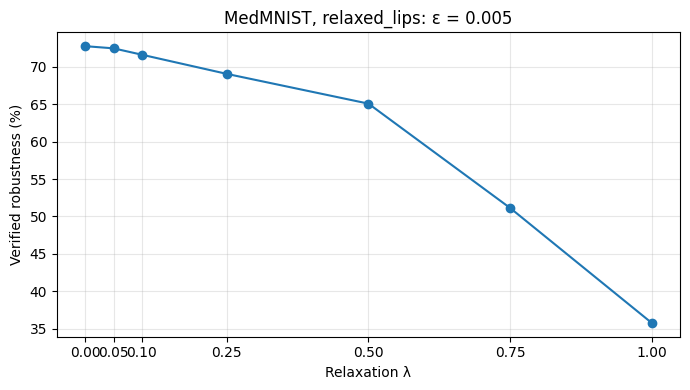

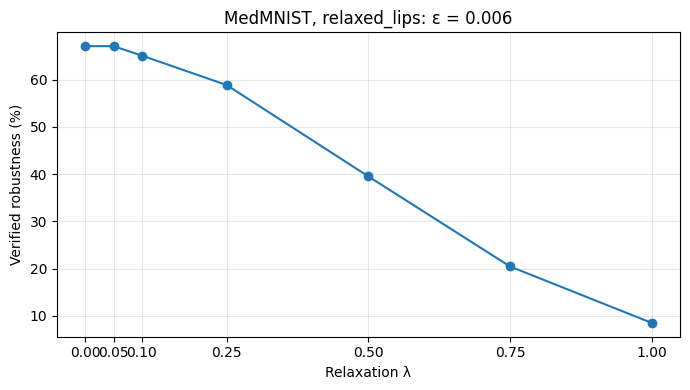

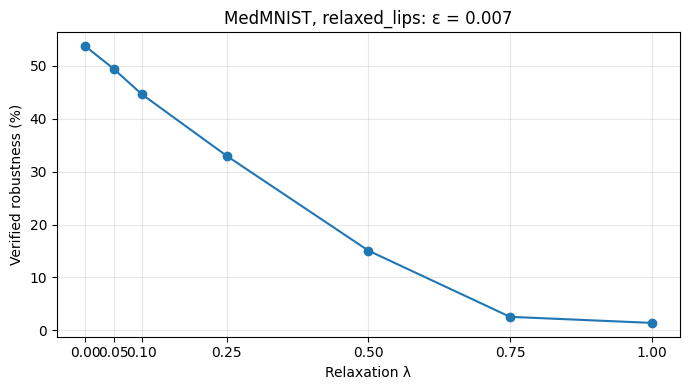

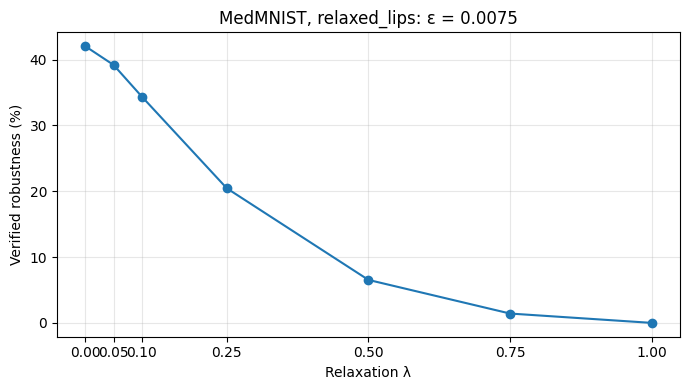

In [38]:
import matplotlib.pyplot as plt
from decimal import Decimal

EPSILONS = list(results)  # Or, for example: [0.0075, 0.006]
Y_LIMITS = None # (0, 100)       # Use None to autoscale.

all_lambdas = sorted({lam for by_lambda in results.values() for lam in by_lambda})

for epsilon in EPSILONS:
    by_lambda = results[epsilon]
    accuracies = [by_lambda.get(lam, float("nan")) for lam in all_lambdas]

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(all_lambdas, accuracies, marker="o")
    ax.set(
        title=f"{DATASET}, {METHOD_NAME}: ε = {Decimal(str(epsilon)):f}",
        xlabel="Relaxation λ",
        ylabel="Verified robustness (%)",
        xticks=all_lambdas,
    )
    if Y_LIMITS is not None:
        ax.set_ylim(*Y_LIMITS)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


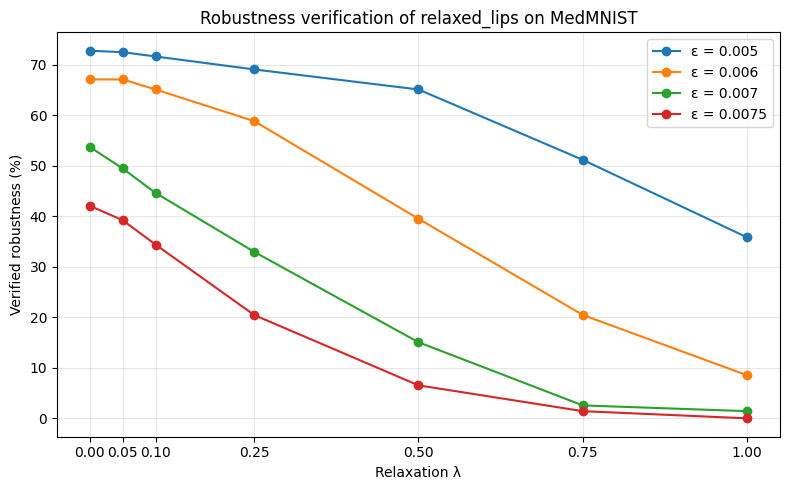

In [39]:
# Combined view using the same EPSILONS and Y_LIMITS as the individual plots.
fig, ax = plt.subplots(figsize=(8, 5))

for epsilon in EPSILONS:
    by_lambda = results[epsilon]
    accuracies = [by_lambda.get(lam, float("nan")) for lam in all_lambdas]
    ax.plot(
        all_lambdas,
        accuracies,
        marker="o",
        label=f"ε = {Decimal(str(epsilon)):f}",
    )

ax.set(
    title=f"Robustness verification of {METHOD_NAME} on {DATASET}",
    xlabel="Relaxation λ",
    ylabel="Verified robustness (%)",
    xticks=all_lambdas,
)
if Y_LIMITS is not None:
    ax.set_ylim(*Y_LIMITS)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
